# 2026/10/22：反復拡張と回転拡張の方法と画質の確認

**画像をどう作るかだけ**を確認するノートブックです。モデルの学習・復元・異常検知の評価は行いません。

| 方法 | 何を変えるか | 1枚の元画像から用意する入力 |
|---|---|---|
| 反復拡張 | 向きも画素値も変えず、同じ画像を繰り返し使う | 全く同じ128×128画像を10回 |
| 現在の回転拡張 | 820×820で向きを変え、その後128×128へ縮小 | 0〜324度、36度刻みの10方向 |
| 過去の回転処理（比較用） | 先に128×128へ縮小してから向きを変える | 同じ10方向。学習は行わず画像だけ比較 |

**区別したいこと**

- 画像のギザギザやぼけの違いを観察しても、それだけで「復元精度やAUROCの差の原因」とは断定できません。
- 学習済み実行20261021_232232_a54302edの保存設定からは、Cの回転時解像度・処理順を確認できません。このノートブックの画像から、その学習履歴を逆算して断定しません。
- 以下の「画像の表示」と、モデルが実際に受け取る128×128の画素配列を区別します。拡大図では表示用の補間を最近傍に固定し、表示時の平滑化を避けます。
- 画像はメモリ内で作り、元画像や拡張画像をファイルとして保存しません。出力図はこのノートブックに残します。

上から順に実行してください。最初の設定で画像ファイル名・比較角度・拡大する範囲を変更できます。

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
from PIL import Image
from torchvision import transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

%matplotlib inline

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'code/261021画像反復と回転拡張による学習効果の比較.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')
TRAIN_DIR = ROOT / 'data/bottle/train/good'
IMAGE_NAME = None  # Noneなら先頭画像。例：'015.png' に変更して別の画像を確認。
ANGLES = tuple(range(0,360,36))
COMPARE_ANGLES = (36,72,144)
ZOOM_BOX = (96,40,128,72)  # 最終128×128画像上の(left,top,right,bottom)。0〜128で指定。
CROP_SIZE = 820
OUTPUT_SIZE = 128
FILL_VALUE = 255
DEMO_ANGLE = 36
SAVED_CONFIG = ROOT / 'saved_models/rotation_control_20261021/20261021_232232_a54302ed/config.json'

paths = sorted(TRAIN_DIR.glob('*.png'), key=lambda p:p.name)
if not paths:
    raise FileNotFoundError(TRAIN_DIR)
image_path = paths[0] if IMAGE_NAME is None else TRAIN_DIR / IMAGE_NAME
if not image_path.is_file():
    raise FileNotFoundError(image_path)
if any(angle not in ANGLES for angle in COMPARE_ANGLES):
    raise ValueError('比較角度はANGLESに含まれる値にしてください。')
left,top,right,bottom = ZOOM_BOX
if not (0<=left<right<=128 and 0<=top<bottom<=128):
    raise ValueError('ZOOM_BOXは最終128×128画像の範囲内にしてください。')

fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic','Meiryo','MS Gothic','Noto Sans CJK JP','IPAexGothic']:
    if font in fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size':11,'axes.unicode_minus':False,'figure.dpi':100})
print(f'確認する画像：{image_path.relative_to(ROOT)}')
print(f'学習用の元画像：{len(paths)}枚 / 反復・回転：各10通り / 学習やモデル推論は行いません。')

確認する画像：data\bottle\train\good\000.png
学習用の元画像：209枚 / 反復・回転：各10通り / 学習やモデル推論は行いません。


## 1. 共通の前処理：画像が入力の数値になるまで

①元画像をRGBとして読む → ②中央820×820を切り出す → ③LANCZOSで128×128へ縮小 → ④グレースケール化 → ⑤0〜1の数値にする、という流れです。

グレースケールの画素値は通常0〜255です。ToTensorは、ここで扱う8bit画像を255で割った0〜1のfloat32テンソルへ変換します。128×128は変わらず、チャンネル数1が付いた形(1,128,128)になります。

切り出しは中心付近を残す処理です。元画像が820より小さい場合、CenterCropは不足分をパディングするため、表示する元画像のサイズも確認してください。

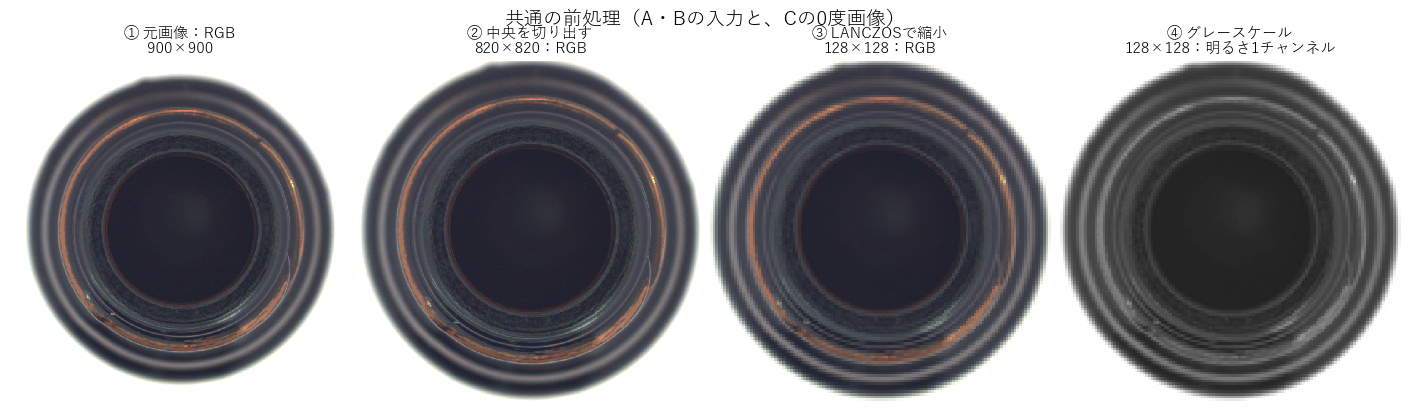

,段階,配列の形,型,最小値,最大値
0,グレースケール画像,"(128, 128)",uint8,33.000000,255.0
1,モデル入力の数値,"(1, 128, 128)",torch.float32,0.129412,1.0


In [2]:
raw = image_path.read_bytes()
source_sha256 = hashlib.sha256(raw).hexdigest()
with Image.open(BytesIO(raw)) as im:
    original = im.convert('RGB').copy()

crop = transforms.CenterCrop(CROP_SIZE)
resize = transforms.Resize((OUTPUT_SIZE,OUTPUT_SIZE), interpolation=transforms.InterpolationMode.LANCZOS)
grayscale = transforms.Grayscale(num_output_channels=1)
to_tensor = transforms.ToTensor()

cropped_rgb = crop(original)
resized_rgb = resize(cropped_rgb)
base_gray = grayscale(resized_rgb)
base_tensor = to_tensor(base_gray)

def finish(high_resolution_image):
    return grayscale(resize(high_resolution_image))

def show_image(ax,image,title):
    array = np.asarray(image)
    if array.ndim==2:
        ax.imshow(array,cmap='gray',vmin=0,vmax=255,interpolation='nearest')
    else:
        ax.imshow(array,interpolation='nearest')
    ax.set_title(title,fontsize=11)
    ax.axis('off')

fig,axes = plt.subplots(1,4,figsize=(14,4),constrained_layout=True)
show_image(axes[0],original,f'① 元画像：RGB\n{original.size[0]}×{original.size[1]}')
show_image(axes[1],cropped_rgb,'② 中央を切り出す\n820×820：RGB')
show_image(axes[2],resized_rgb,'③ LANCZOSで縮小\n128×128：RGB')
show_image(axes[3],base_gray,'④ グレースケール\n128×128：明るさ1チャンネル')
fig.suptitle('共通の前処理（A・Bの入力と、Cの0度画像）',fontsize=14)
plt.show()
plt.close(fig)

display(pd.DataFrame([
    {'段階':'グレースケール画像','配列の形':str(np.asarray(base_gray).shape),
     '型':str(np.asarray(base_gray).dtype),'最小値':int(np.asarray(base_gray).min()),'最大値':int(np.asarray(base_gray).max())},
    {'段階':'モデル入力の数値','配列の形':str(tuple(base_tensor.shape)),
     '型':str(base_tensor.dtype),'最小値':float(base_tensor.min()),'最大値':float(base_tensor.max())},
]))
assert tuple(base_tensor.shape)==(1,128,128)
assert np.allclose(base_tensor.numpy()[0],np.asarray(base_gray,dtype=np.float32)/255.0)

## 2. 反復拡張：同じ画像を10回使う

**画像加工は追加しません。** 共通の前処理で得た同じ画像を繰り返し参照します。

現在の学習コードでも、元画像1枚について同じ画像を返す番号を10個割り当てています。10個のPNGを新たに保存する方法ではありません。下のコードは1枚についての仕組みを取り出したものです。

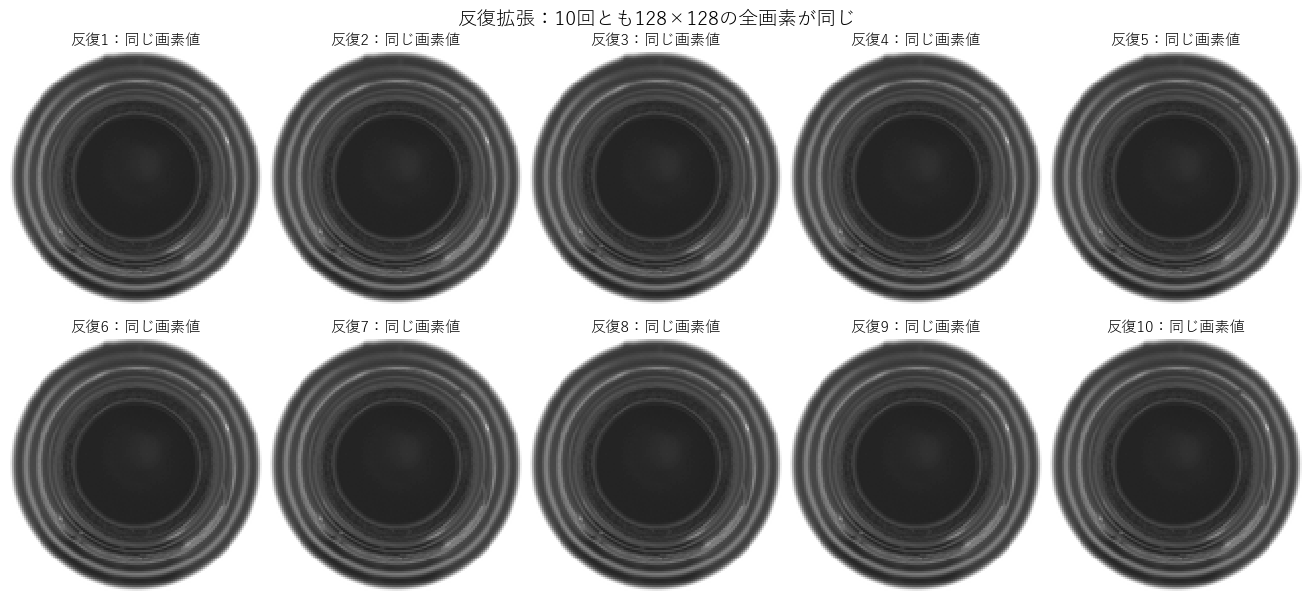

,反復番号,元の128×128画像と全画素一致
0,1,True
1,2,True
2,3,True
3,4,True
4,5,True
5,6,True
6,7,True
7,8,True
8,9,True
9,10,True


In [3]:
# 同じ画像への参照を10個用意する。画素を加工したり、PNGを書き出したりしない。
repeat_images = [base_gray for _ in ANGLES]
repeat_arrays = [np.asarray(image) for image in repeat_images]
repeat_checks = [np.array_equal(np.asarray(base_gray),array) for array in repeat_arrays]
assert len(repeat_images)==10 and all(repeat_checks)

fig,axes = plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
for index,(ax,image) in enumerate(zip(axes.ravel(),repeat_images),1):
    show_image(ax,image,f'反復{index}：同じ画素値')
fig.suptitle('反復拡張：10回とも128×128の全画素が同じ',fontsize=14)
plt.show()
plt.close(fig)
display(pd.DataFrame({'反復番号':range(1,11),'元の128×128画像と全画素一致':repeat_checks}))

## 3. 現在の回転拡張：820×820で回転してから縮小

1. 中央820×820のRGB画像を用意する。
2. 元の820×820画像から、0・36・72・…・324度の画像をそれぞれ作る。
3. 各画像を128×128へLANCZOSで縮小し、グレースケール化する。
4. 最後に0〜1の数値へ変換して、モデルへの入力にする。

**36度回転した画像をさらに36度回して72度を作る、という連続処理ではありません。** 毎回同じ切り出し画像から直接回転します。0度では回転処理を省略し、反復画像と同じ入力を使います。

回転は最近傍補間（NEAREST）、画像外から来る部分は白（255）、expand=Falseで820×820を維持します。

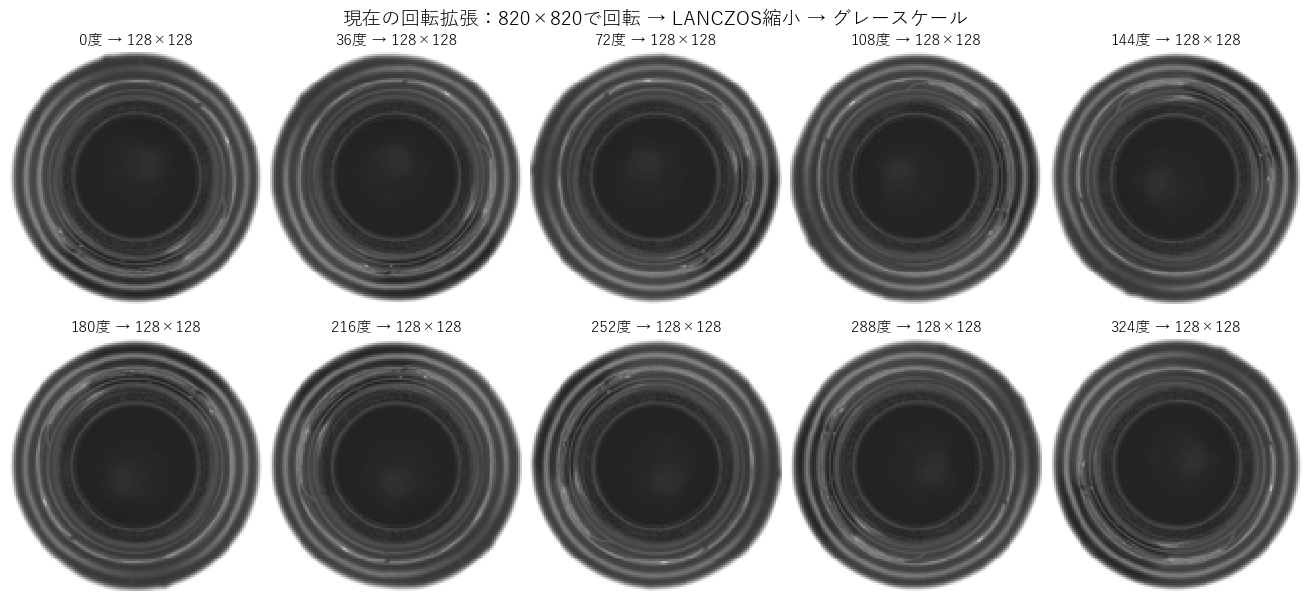

0度画像と反復画像：128×128の全画素・0〜1の入力数値とも完全一致。


In [4]:
def rotate_nearest(image,angle,fill=FILL_VALUE):
    if angle==0:
        return image
    return TF.rotate(image,angle=angle,
                     interpolation=transforms.InterpolationMode.NEAREST,
                     expand=False,fill=fill)

# 全角度を同じcropped_rgbから直接作る。前の回転結果は使わない。
current_rotated_images = {angle:finish(rotate_nearest(cropped_rgb,angle)) for angle in ANGLES}
current_rotated_tensors = {angle:to_tensor(image) for angle,image in current_rotated_images.items()}
assert all(image.size==(128,128) for image in current_rotated_images.values())
assert np.array_equal(np.asarray(current_rotated_images[0]),np.asarray(base_gray))
assert np.array_equal(current_rotated_tensors[0].numpy(),base_tensor.numpy())

fig,axes = plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
for ax,angle in zip(axes.ravel(),ANGLES):
    show_image(ax,current_rotated_images[angle],f'{angle}度 → 128×128')
fig.suptitle('現在の回転拡張：820×820で回転 → LANCZOS縮小 → グレースケール',fontsize=14)
plt.show()
plt.close(fig)
print('0度画像と反復画像：128×128の全画素・0〜1の入力数値とも完全一致。')

## 4. 過去と現在の方法を、同じ画像・同じ角度で比べる

| 方法 | 処理順 |
|---|---|
| 過去：縮小後に回転 | 820×820切り出し → 128×128へLANCZOS縮小 → グレースケール → 最近傍回転 |
| 現在：回転後に縮小 | 820×820切り出し → 最近傍回転 → 128×128へLANCZOS縮小 → グレースケール |

過去は128×128という小さなマス目上で回転するため、輪郭や細い模様に階段状の変化が現れやすくなります。現在は細かいマス目の段階で回転し、最後の縮小で画素をまとめます。

ただし、LANCZOS縮小も画素を変える処理です。ぼけや細部の変化が完全になくなるわけではありません。新旧では回転の段階と、それに伴うグレースケール化の位置が異なります。

赤枠が次の拡大図で使う範囲です。各列では同じ角度・同じ128×128上の座標を比べます。元の0度画像と回転画像は被写体の位置関係が変わるため、その差をそのまま画質劣化とは扱いません。

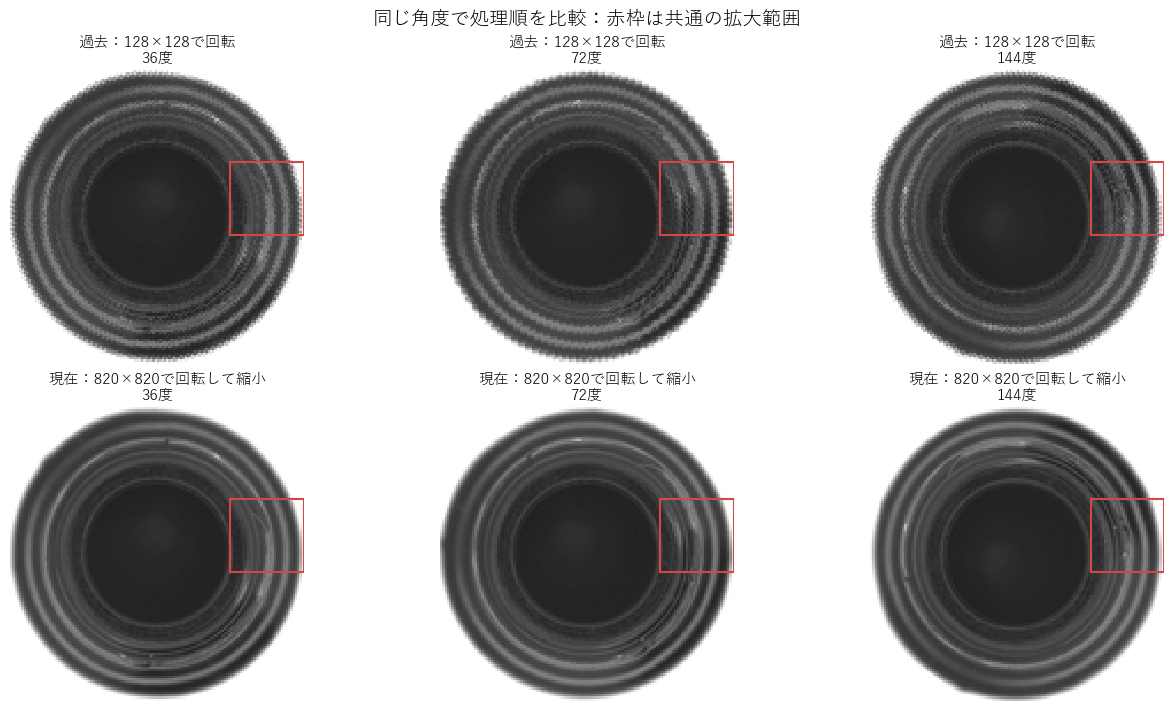

In [5]:
old_rotated_images = {angle:rotate_nearest(base_gray,angle) for angle in ANGLES}
assert np.array_equal(np.asarray(old_rotated_images[0]),np.asarray(current_rotated_images[0]))
fig,axes = plt.subplots(2,len(COMPARE_ANGLES),figsize=(4.3*len(COMPARE_ANGLES),7),squeeze=False,constrained_layout=True)
for column,angle in enumerate(COMPARE_ANGLES):
    for row,(label,images) in enumerate([
        ('過去：128×128で回転',old_rotated_images),
        ('現在：820×820で回転して縮小',current_rotated_images),
    ]):
        ax=axes[row,column]
        show_image(ax,images[angle],f'{label}\n{angle}度')
        ax.add_patch(Rectangle((left-0.5,top-0.5),right-left,bottom-top,
                               fill=False,edgecolor='#d24747',linewidth=1.5))
fig.suptitle('同じ角度で処理順を比較：赤枠は共通の拡大範囲',fontsize=14)
plt.show()
plt.close(fig)

## 5. 輪郭を拡大して確認する

32×32などの小さな領域を大きく表示します。**この拡大で画像データの解像度は増えません。** 表示の補間を最近傍に固定し、1ピクセルずつの様子を見ます。

上段と下段の角度・座標・表示の明るさの範囲は同じです。輪郭のギザギザ、模様の途切れ、ぼけ方を観察してください。見た目が滑らかということだけで、異常検知に有利とは断定しません。

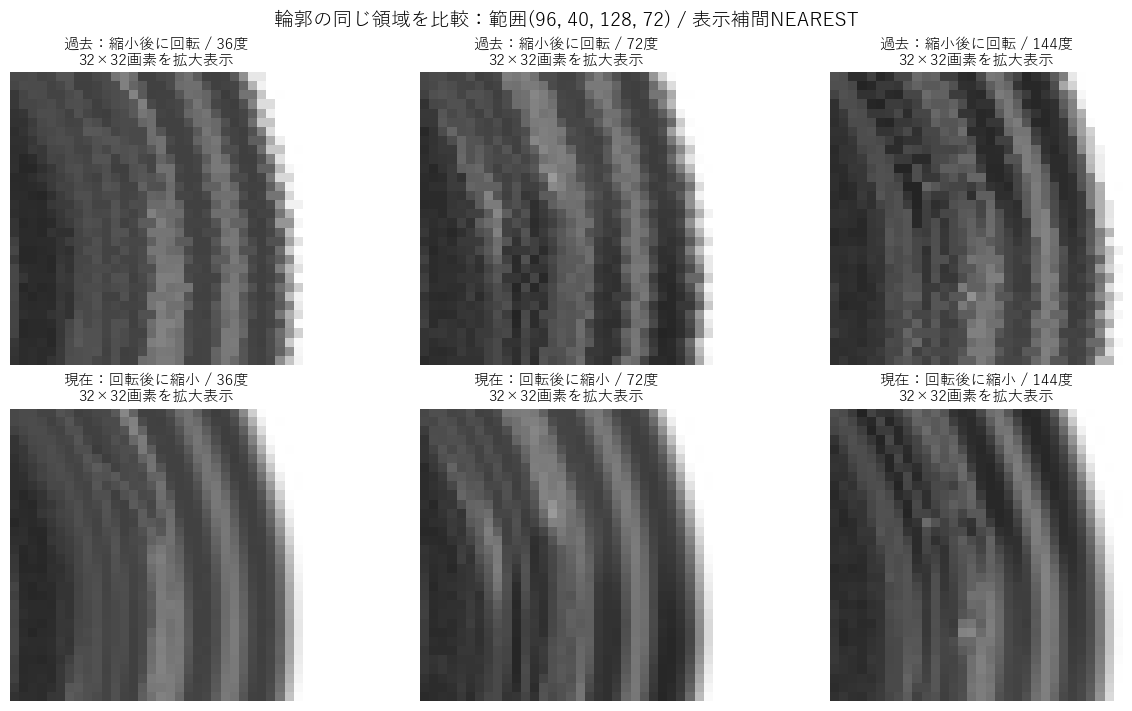

In [6]:
fig,axes = plt.subplots(2,len(COMPARE_ANGLES),figsize=(4.1*len(COMPARE_ANGLES),7),squeeze=False,constrained_layout=True)
for column,angle in enumerate(COMPARE_ANGLES):
    for row,(label,images) in enumerate([
        ('過去：縮小後に回転',old_rotated_images),
        ('現在：回転後に縮小',current_rotated_images),
    ]):
        patch = images[angle].crop(ZOOM_BOX)
        assert patch.size==(right-left,bottom-top)
        show_image(axes[row,column],patch,f'{label} / {angle}度\n{patch.width}×{patch.height}画素を拡大表示')
fig.suptitle(f'輪郭の同じ領域を比較：範囲{ZOOM_BOX} / 表示補間NEAREST',fontsize=14)
plt.show()
plt.close(fig)

## 6. 補間・白埋め・画像端の切り取りは何をしているか

| 設定 | 処理の意味 |
|---|---|
| 回転のNEAREST（最近傍） | 回転後の画素の値に、最も近い元の1画素の値を使う。斜めの線が階段状になり得る |
| 縮小のLANCZOS | 周辺画素を重み付けして、新しい小さなマス目の値を作る。情報を追加して復元する処理ではない |
| fill=255 | 回転で参照元がなくなった領域を白で埋める。元の白い背景の画素を保護する指定ではない |
| expand=False | 回転後も同じサイズを維持する。回転で枠の外へ出た部分は結果に含まれない |

右の図は、元の画像領域が回転後の枠内に残る場所を示す**説明用のマスク**です。白は元画像を参照できる領域、黒は白埋めされる領域です。ボトルやキズの正解マスクではありません。

対象が画像端まで広がる場合は、一部が切れる可能性があります。今回選んだ画像で対象が切れているかどうかは、実際の画像を見て確認します。

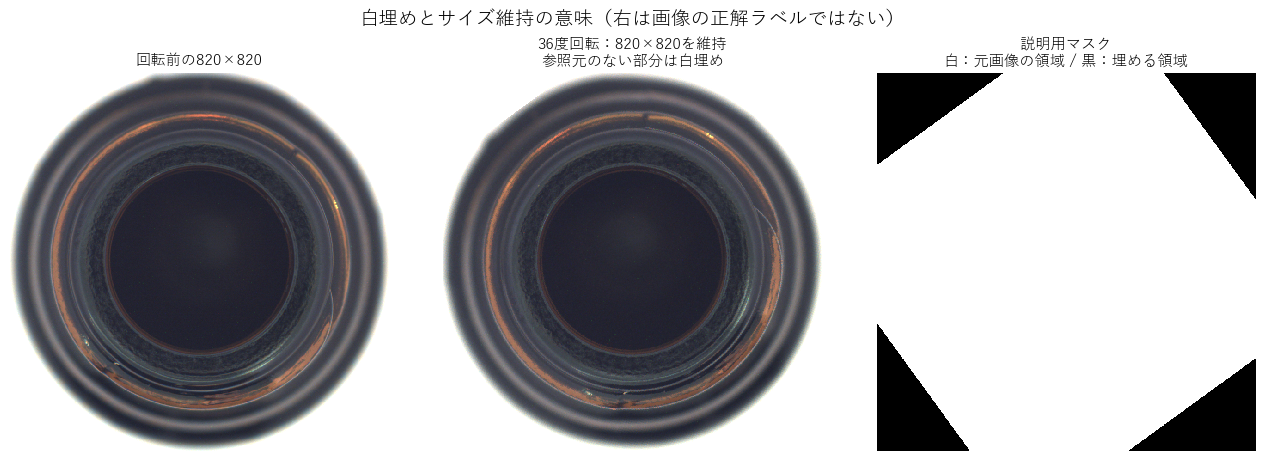

In [7]:
high_rotated = rotate_nearest(cropped_rgb,DEMO_ANGLE)
# 元画像の有効領域だけを可視化するための、説明用マスク。
valid_source = Image.new('L',cropped_rgb.size,color=255)
valid_rotated = rotate_nearest(valid_source,DEMO_ANGLE,fill=0)
fig,axes = plt.subplots(1,3,figsize=(13,4.5),constrained_layout=True)
show_image(axes[0],cropped_rgb,'回転前の820×820')
show_image(axes[1],high_rotated,f'{DEMO_ANGLE}度回転：820×820を維持\n参照元のない部分は白埋め')
show_image(axes[2],valid_rotated,'説明用マスク\n白：元画像の領域 / 黒：埋める領域')
fig.suptitle('白埋めとサイズ維持の意味（右は画像の正解ラベルではない）',fontsize=14)
plt.show()
plt.close(fig)

## 7. 209枚から2,090枚になる数え方と、学習コードへの対応

- 反復拡張：209枚×10回＝延べ2,090サンプル。独立な新しい画像が増えたわけではありません。
- 回転拡張：209枚×10方向＝2,090サンプル。0度の元の向きも含みます。
- 現在の学習コードでは、番号を10で割った商が元画像番号、余りが反復番号または回転番号です。
- Bでは余りが変わっても同じ元画像の入力を返し、Cでは余りに対応する角度の入力を返します。
- 画像番号や角度は記録用で、モデルへは画像の数値だけを渡します。同じ元画像の関係を直接教えるものではありません。

下表はこの番号付けの例です。保存ファイル名を新しく作っているわけではありません。

In [8]:
mapping=[]
for sample_index in [0,1,9,10,11,len(paths)*10-1]:
    parent,variant = divmod(sample_index,10)
    mapping.append({
        'サンプル番号（0始まり）':sample_index,
        '元画像':paths[parent].name,
        '反復番号（0始まり）':variant,
        'Bの角度':0,
        'Cの角度':ANGLES[variant],
    })
display(pd.DataFrame(mapping))
display(pd.DataFrame([
    {'方法':'元画像のみ','元画像数':len(paths),'使用回数・方向数':1,'延べサンプル数':len(paths)},
    {'方法':'反復拡張','元画像数':len(paths),'使用回数・方向数':10,'延べサンプル数':len(paths)*10},
    {'方法':'回転拡張','元画像数':len(paths),'使用回数・方向数':10,'延べサンプル数':len(paths)*10},
]))

# 0度と反復が一致することだけを数値で確認。回転前後の差を画質スコアにはしない。
assert all(np.array_equal(np.asarray(im),np.asarray(base_gray)) for im in repeat_images)
assert np.array_equal(np.asarray(base_gray),np.asarray(current_rotated_images[0]))
assert hashlib.sha256(image_path.read_bytes()).hexdigest()==source_sha256

if SAVED_CONFIG.is_file():
    saved_config = json.loads(SAVED_CONFIG.read_text(encoding='utf-8'))
    saved_rotation_stage = saved_config.get('rotation_stage','記録なし：学習済みCの回転時解像度・処理順は未確認')
else:
    saved_rotation_stage = '対象の学習設定ファイルが見つかりません。画像作成方法の説明には影響しません。'

record = {
    'date_jst':'2026-10-22',
    'source_image':image_path.relative_to(ROOT).as_posix(),
    'source_sha256':source_sha256,
    'source_size':list(original.size),
    'crop_size':list(cropped_rgb.size),
    'final_size':list(base_gray.size),
    'angles':list(ANGLES),
    'current_pipeline':'CenterCrop820 RGB -> Rotate NEAREST at820 (skip0) -> Resize128 LANCZOS -> Grayscale -> ToTensor',
    'previous_pipeline':'CenterCrop820 RGB -> Resize128 LANCZOS -> Grayscale -> Rotate NEAREST at128 (skip0) -> ToTensor',
    'rotation_fill':255,'rotation_expand':False,
    'repeat_pixels_all_identical':all(repeat_checks),
    'current_zero_degree_equals_repeat':True,
    'zoom_box':list(ZOOM_BOX),
    'saved_training_rotation_stage':saved_rotation_stage,
    'versions':{name:importlib.metadata.version(name) for name in ['torch','torchvision','Pillow','numpy','matplotlib']},
}
print(json.dumps(record,ensure_ascii=False,indent=2))

,サンプル番号（0始まり）,元画像,反復番号（0始まり）,Bの角度,Cの角度
0,0,000.png,0,0,0
1,1,000.png,1,0,36
2,9,000.png,9,0,324
3,10,001.png,0,0,0
4,11,001.png,1,0,36
5,2089,208.png,9,0,324


,方法,元画像数,使用回数・方向数,延べサンプル数
0,元画像のみ,209,1,209
1,反復拡張,209,10,2090
2,回転拡張,209,10,2090


{
  "date_jst": "2026-10-22",
  "source_image": "data/bottle/train/good/000.png",
  "source_sha256": "8a25eb07475a5102f4823fefd82662dd65f8f2a0a333bf958124ceeee38f0e38",
  "source_size": [
    900,
    900
  ],
  "crop_size": [
    820,
    820
  ],
  "final_size": [
    128,
    128
  ],
  "angles": [
    0,
    36,
    72,
    108,
    144,
    180,
    216,
    252,
    288,
    324
  ],
  "current_pipeline": "CenterCrop820 RGB -> Rotate NEAREST at820 (skip0) -> Resize128 LANCZOS -> Grayscale -> ToTensor",
  "previous_pipeline": "CenterCrop820 RGB -> Resize128 LANCZOS -> Grayscale -> Rotate NEAREST at128 (skip0) -> ToTensor",
  "rotation_fill": 255,
  "rotation_expand": false,
  "repeat_pixels_all_identical": true,
  "current_zero_degree_equals_repeat": true,
  "zoom_box": [
    96,
    40,
    128,
    72
  ],
  "saved_training_rotation_stage": "記録なし：学習済みCの回転時解像度・処理順は未確認",
  "versions": {
    "torch": "2.12.0",
    "torchvision": "0.27.0",
    "Pillow": "12.2.0",
    "numpy": "2.4.6

## この資料から確認できること

反復拡張では画素を変えず、回転拡張では画素の位置を変え、補間・縮小を伴います。現在の回転後縮小と過去の縮小後回転では、同じ角度でも最終的な画素値や輪郭の見え方が変わり得ます。

**画質の違いが今回の復元誤差・AUROCの差の原因かは、この資料だけでは判断できません。** また、保存済みCモデルがどちらの処理で学習されたかは、保存された設定から未確認です。

処理を追う元のコード：
- 現在の比較学習：261021画像反復と回転拡張による学習効果の比較.ipynb
- 過去の回転画像生成：260718画像データの拡張.ipynb

このノートブックは画像の作り方を説明するもので、モデルの学習・推論や性能評価の結果を追加するものではありません。